In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (7, 4)

def check(label, test, hint=""):
    """Self-check helper: prints ✅ or ❌ (with a hint)."""
    try:
        ok = bool(test())
    except Exception as e:
        ok, hint = False, f"{hint}  (error: {type(e).__name__}: {e})"
    print(("✅ " if ok else "❌ ") + label + ("" if ok else f"\n   hint: {hint}"))

print("Ready!")

Ready!


In [3]:
rng = np.random.default_rng(42)
n = 500

area = rng.normal(900, 300, n).clip(300, 2500).round()              # sq ft
bedrooms = np.clip(np.round(area / 350 + rng.normal(0, 0.7, n)), 1, 6)
age = rng.uniform(0, 120, n).round()                                # years
distance = rng.uniform(1, 20, n).round(1)                           # miles from central London
random_noise = rng.normal(0, 1, n).round(2)                         # a useless feature

price = (300 + 0.45 * area + 25 * bedrooms - 0.8 * age
         - 18 * distance + rng.normal(0, 45, n))                    # £ thousands

df = pd.DataFrame({
    "area": area, "bedrooms": bedrooms, "age": age,
    "distance": distance, "random_noise": random_noise,
    "price": price.clip(150).round()
})
print(df.shape)
df.head()

(500, 6)


,area,bedrooms,age,distance,random_noise,price
0,991.0,4.0,78.0,10.1,0.39,638.0
1,588.0,2.0,41.0,15.9,0.55,264.0
2,1125.0,3.0,49.0,15.2,0.23,603.0
3,1182.0,2.0,53.0,16.5,0.97,508.0
4,315.0,1.0,15.0,9.5,0.09,333.0


In [4]:
df.describe()

,area,bedrooms,age,distance,random_noise,price
count,500.000,500.000,500.000,500.000,500.000,500.000
mean,897.246,2.582,59.898,10.644,0.005,532.980
std,285.285,1.068,35.047,5.461,1.012,191.048
min,300.000,1.000,0.000,1.000,-3.060,150.000
25%,699.750,2.000,27.000,5.775,-0.663,400.750
50%,901.000,3.000,58.000,10.400,0.045,539.500
75%,1076.250,3.000,91.000,15.500,0.630,661.000
max,1774.000,6.000,120.000,20.000,2.860,1202.000


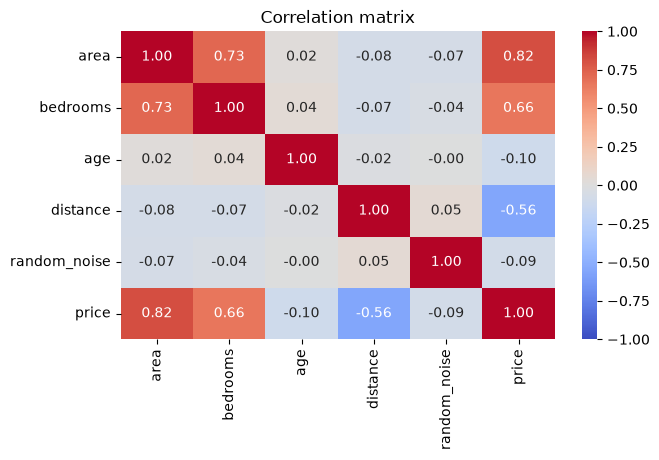

price           1.000
area            0.820
bedrooms        0.662
random_noise   -0.086
age            -0.103
distance       -0.560
Name: price, dtype: float64

In [5]:
#2 · Understand relationships first: correlation ▶️
# Before modelling, look at how each feature moves with price.
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

corr["price"].sort_values(ascending=False)

In [7]:
most_negative = corr[["random_noise", "age", "distance"]]
print(most_negative)

              random_noise    age  distance
area                -0.070  0.022    -0.077
bedrooms            -0.039  0.040    -0.073
age                 -0.001  1.000    -0.023
distance             0.049 -0.023     1.000
random_noise         1.000 -0.001     0.049
price               -0.086 -0.103    -0.560


In [8]:
check("Exercise 1", lambda: most_negative == df.corr(numeric_only=True)["price"].drop("price").idxmin(),
      "drop 'price' from corr['price'], then use .idxmin()")

❌ Exercise 1
   hint: drop 'price' from corr['price'], then use .idxmin()  (error: ValueError: The truth value of a DataFrame is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().)


slope (coef_)      = 0.543  → each extra sq ft adds about £543
intercept_         = 43.7


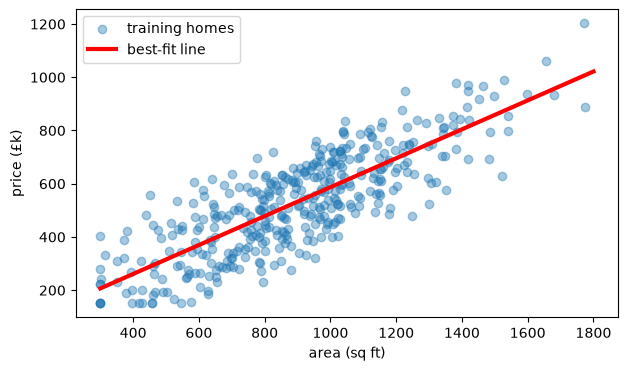

In [9]:
# 3 · Simple Linear Regression ▶️
# One feature (area) → one target (price).


X_simple = df[["area"]]          # double brackets → a 2-D table
y = df["price"]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_simple, y, test_size=0.2, random_state=42)

simple = LinearRegression()
simple.fit(Xs_train, ys_train)

print(f"slope (coef_)      = {simple.coef_[0]:.3f}  → each extra sq ft adds about £{simple.coef_[0]*1000:,.0f}")
print(f"intercept_         = {simple.intercept_:.1f}")

plt.scatter(Xs_train, ys_train, alpha=0.4, label="training homes")
xx = np.linspace(300, 1800, 50).reshape(-1, 1)
plt.plot(xx, simple.predict(pd.DataFrame(xx, columns=["area"])), "r", lw=3, label="best-fit line")
plt.xlabel("area (sq ft)"); plt.ylabel("price (£k)"); plt.legend(); plt.show()

In [10]:
# ✏️ Exercise 2 — make a prediction
# Use the trained simple model to predict the price of a 1,200 sq ft home. 
# Store the number (in £k) in pred_1200. Tip: predict expects a table with the same column name: pd.DataFrame({"area": [1200]})
# Create a DataFrame with the same column name as training data

pred_1200 = simple.predict(pd.DataFrame({"area": [1200]}))[0]

print(f"Predicted price for a 1,200 sq ft home: £{pred_1200:.1f}k")

Predicted price for a 1,200 sq ft home: £695.7k


In [11]:

# ✔️ CHECK
check("Exercise 2", lambda: abs(pred_1200 - (simple.intercept_ + simple.coef_[0] * 1200)) < 1e-6,
      "simple.predict(pd.DataFrame({'area': [1200]}))[0]")

✅ Exercise 2


In [12]:
# 4 · Under the hood: Gradient Descent ▶️✏️
# How does a model find the best line? It starts with any line and repeatedly steps "downhill" on the error.

x = np.array([4, 6, 8])
y_small = np.array([3, 4, 5])

def run_gd(lr, steps=100):
    m, c = 0.0, 0.0
    n_pts = len(x)
    for _ in range(steps):
        error = (m * x + c) - y_small
        dm = (2 / n_pts) * (error * x).sum()
        dc = (2 / n_pts) * error.sum()
        m = m - lr * dm      # step downhill for m
        c = c - lr * dc      # step downhill for c
    return ((m * x + c - y_small) ** 2).mean(), m, c

print(run_gd(0.01))

(np.float64(0.042714333378310654), np.float64(0.6223301280687771), np.float64(0.21302326234330066))


In [13]:
# ✔️ CHECK
check("Exercise 3", lambda: run_gd(0.01)[0] < 0.05, "m = m - lr * dm  and  c = c - lr * dc")

# ▶️ Now compare learning rates
for lr in [0.002, 0.01, 0.025, 0.03]:
    mse, m, c = run_gd(lr, steps=100)
    print(f"lr={lr:<6} → MSE after 100 steps = {mse:,.4f}   (m={m:.3f}, c={c:.3f})")

✅ Exercise 3
lr=0.002  → MSE after 100 steps = 0.0530   (m=0.636, c=0.123)
lr=0.01   → MSE after 100 steps = 0.0427   (m=0.622, c=0.213)
lr=0.025  → MSE after 100 steps = 0.3186   (m=0.515, c=0.344)
lr=0.03   → MSE after 100 steps = 87,401,894,750,216,049,362,424,823,808.0000   (m=-46422880076496.641, c=-7216117825780.476)


In [14]:
# 5 · Multiple Linear Regression + evaluation ▶️
# Now use all features. We create one train/test split and reuse it for every model from here on.


features = ["area", "bedrooms", "age", "distance", "random_noise"]
X = df[features]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr_model = LinearRegression().fit(X_train, y_train)
y_pred = lr_model.predict(X_test)

pd.Series(lr_model.coef_, index=features).round(3)

area             0.467
bedrooms        21.856
age             -0.754
distance       -17.658
random_noise    -1.435
dtype: float64

In [ ]:
# Exercise 4 — build the metrics yourself
#


def my_mae(actual, pred):
    return np.mean(np.abs(actual - pred))

def my_rmse(actual, pred):
    return np.sqrt(np.mean((actual - pred) ** 2))

def my_r2(actual, pred):
    ss_res = np.sum((actual - pred) ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)
    return 1 - (ss_res / ss_tot)

print(my_mae(y_test, y_pred), my_rmse(y_test, y_pred), my_r2(y_test, y_pred))

41.793368939302255 48.66390132675253 0.9338209618765554
